In [1]:
from keras.layers import Concatenate
import seaborn as sb
import os
from keras.layers import Input
import pandas as pd
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report,confusion_matrix
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import MaxPooling2D, Flatten, Conv2D, Dense, BatchNormalization, GlobalAveragePooling2D, Dropout
from tensorflow.keras.applications.densenet import DenseNet169
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2

# Data Preprocessing and Preparation

In [2]:
m_dir = 'Chest_Xray/'
train_dir = m_dir + 'train/'
test_dir = m_dir + 'test/'
val_dir = m_dir + 'val/'
train_p_dir = m_dir + 'train/PNEUMONIC/'
train_n_dir = m_dir + 'train/NORMAL/'

In [3]:
train_datagen = ImageDataGenerator(rescale = 1.0 / 255, horizontal_flip = True)
test_datagen = ImageDataGenerator(rescale = 1.0 / 255)
val_datagen = ImageDataGenerator(rescale = 1.0 / 255)

In [4]:
img_w, img_h = [224, 224]
batch_size = 32
train_generator = train_datagen.flow_from_directory(train_dir, target_size = (img_w, img_h), batch_size = batch_size, class_mode = 'binary', shuffle = True)
test_generator = test_datagen.flow_from_directory(test_dir, target_size = (img_w, img_h), batch_size = batch_size, class_mode = 'binary')
val_generator = val_datagen.flow_from_directory(val_dir, target_size = (img_w, img_h), batch_size = batch_size, class_mode = 'binary')

Found 5216 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Found 16 images belonging to 2 classes.


# Model Building

In [5]:
in_shape = (224, 224, 3)
in_layer = Input(shape = in_shape)
mobilenet = MobileNetV2(weights = 'imagenet', input_shape = in_shape, include_top = False)
densenet = DenseNet169(weights = 'imagenet', input_shape = in_shape, include_top = False)
for layer in mobilenet.layers:
    layer.trainable = False
for layer in densenet.layers:
    layer.trainable = False
model_mobilenet = mobilenet(in_layer)
model_mobilenet = GlobalAveragePooling2D()(model_mobilenet)
output_mobilenet = Flatten()(model_mobilenet)
model_densenet = densenet(in_layer)
model_densenet = GlobalAveragePooling2D()(model_densenet)
output_densenet = Flatten()(model_densenet)
concatenated = Concatenate()([output_mobilenet, output_densenet])
X = BatchNormalization()(concatenated)
X = Dense(256, activation = 'relu')(X)
X = Dropout(0.5)(X)
X = BatchNormalization()(X)
X = Dense(128, activation = 'relu')(X)
X = Dropout(0.5)(X)
X = Dense(1, activation = 'sigmoid')(X)
model = tf.keras.models.Model(inputs = in_layer, outputs = X)

In [6]:
optim = Adam(learning_rate = 0.0001)
model.compile(loss = 'binary_crossentropy', optimizer = optim, metrics = ['accuracy'])

In [7]:
EarlyStopping = EarlyStopping(monitor = 'val_accuracy', min_delta = 0.01, patience = 6, verbose = 1, mode = 'auto', baseline = None, restore_best_weights = True)
rlr = ReduceLROnPlateau(monitor = "val_accuracy", factor = 0.01, patience = 6, verbose = 0, mode = "max", min_delta = 0.01)
model_save = ModelCheckpoint('./stacked_model.h5', save_best_only = True, save_weights_only = False, monitor = 'val_loss', mode = 'min', verbose = 1)

In [8]:
train_samples = 5216
validation_samples = 16
test_samples = 624
epochs = 30  
batch_size = 32

In [74]:
history = model.fit(train_generator, steps_per_epoch = train_samples // batch_size, epochs = epochs, validation_data = test_generator, callbacks = [EarlyStopping, rlr, model_save])

Epoch 1/30
163/163 [==============================] - ETA: 0s - loss: 0.3560 - accuracy: 0.8434
Epoch 1: val_loss improved from inf to 0.33424, saving model to .\stacked_model.h5
163/163 [==============================] - 112s 563ms/step - loss: 0.3560 - accuracy: 0.8434 - val_loss: 0.3342 - val_accuracy: 0.8542 - lr: 1.0000e-04
Epoch 2/30
163/163 [==============================] - ETA: 0s - loss: 0.1834 - accuracy: 0.9312
Epoch 2: val_loss did not improve from 0.33424
163/163 [==============================] - 79s 483ms/step - loss: 0.1834 - accuracy: 0.9312 - val_loss: 0.3572 - val_accuracy: 0.8542 - lr: 1.0000e-04
Epoch 3/30
163/163 [==============================] - ETA: 0s - loss: 0.1428 - accuracy: 0.9486
Epoch 3: val_loss did not improve from 0.33424
163/163 [==============================] - 78s 480ms/step - loss: 0.1428 - accuracy: 0.9486 - val_loss: 0.3716 - val_accuracy: 0.8606 - lr: 1.0000e-04
Epoch 4/30
163/163 [==============================] - ETA: 0s - loss: 0.1145 - ac

# Prediction and Testing

In [9]:
model = tf.keras.models.load_model('stacked_model.h5')

In [10]:
def process_image(image):
    image = image / 255
    image = cv2.resize(image, (224,224))
    return image

In [11]:
def predict(image_path, model):
    im = cv2.imread(image_path)
    test_image = np.asarray(im)
    processed_test_image = process_image(test_image)
    processed_test_image = np.expand_dims(processed_test_image, axis = 0)
    ps = model.predict(processed_test_image)
    return ps

In [12]:
def testing(model, test_df):
    base_pred = [] 
    for image in test_df.img_path:
        base_pred.append(predict(image, model)[0][0])
    final_base_pred = np.where(np.array(base_pred) > 0.5, 1, 0)
    actual_label = test_df['label']
    print(classification_report(actual_label, final_base_pred))
    matrix = confusion_matrix(actual_label, final_base_pred)
    sb.heatmap(matrix, square = True, annot = True, fmt = 'd', cbar = False, xticklabels = ['0', '1'], yticklabels = ['0', '1'])
    plt.xlabel('Predicted label')
    plt.ylabel('True label')

In [13]:
def getTestDf(n_dir, p_dir):
    imgPaths = []
    labels = []
    for filename in os.listdir(n_dir):
        if filename.lower().endswith(('.jpeg')):
            imgPaths.append(n_dir + filename)
            labels.append(0)
    for filename in os.listdir(p_dir):
        if filename.lower().endswith(('.jpeg')):
            imgPaths.append(p_dir + filename)
            labels.append(1)
    imgPaths = np.array(imgPaths)
    labels = np.array(labels)
    indices = np.arange(imgPaths.shape[0])
    np.random.shuffle(indices)
    imgPaths = imgPaths[indices]
    labels = labels[indices]
    test_df = pd.DataFrame({'img_path': imgPaths, 'label': labels})
    return test_df

In [14]:
n_dir = 'Chest_Xray/test/NORMAL/'
p_dir = 'Chest_Xray/test/PNEUMONIA/'

In [15]:
test_df = getTestDf(n_dir, p_dir)

1/1 [==============================] - 0s 119ms/step


1/1 [==============================] - 0s 95ms/step


1/1 [==============================] - 0s 96ms/step


1/1 [==============================] - 0s 94ms/step
              precision    recall  f1-score   support

           0       0.92      0.67      0.78       234
           1       0.83      0.96      0.89       390

    accuracy                           0.85       624
   macro avg       0.87      0.82      0.83       624
weighted avg       0.86      0.85      0.85       624



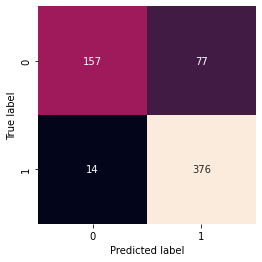

In [16]:
testing(model, test_df)

In [82]:
n_dir = 'Chest_Xray/val/NORMAL/'
p_dir = 'Chest_Xray/val/PNEUMONIA/'

In [83]:
test_df = getTestDf(n_dir, p_dir)

1/1 [==============================] - 0s 97ms/step
              precision    recall  f1-score   support

           0       1.00      0.88      0.93         8
           1       0.89      1.00      0.94         8

    accuracy                           0.94        16
   macro avg       0.94      0.94      0.94        16
weighted avg       0.94      0.94      0.94        16



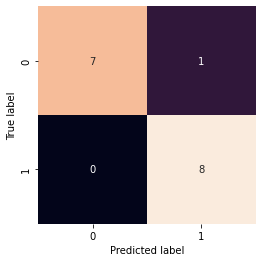

In [84]:
testing(model, test_df)